### Imports

In [1]:
from selenium import webdriver
from selenium.webdriver.support.wait import WebDriverWait
from selenium.webdriver.support import expected_conditions
from selenium.webdriver.common.by import By
from selenium.webdriver.common.keys import Keys
from selenium.webdriver.common.action_chains import ActionChains
from selenium.webdriver.support.ui import Select

import pandas as pd
import pickle
import os
import sys
import warnings
import time

from bs4 import BeautifulSoup
import requests
headers = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/58.0.3029.110 Safari/537.3'}
headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36", "Accept": "text/html,application/xhtml+xml,application/xml;q=0.9,*/*;q=0.8", "Accept-Language": "en-US,en;q=0.9", "Referer": "https://www.ewg.org/tapwater/", "Connection": "keep-alive"}



from selenium.webdriver.edge.options import Options

edge_options = Options()
#edge_options.add_argument('--headless')
edge_options.add_argument("--disable-images")  # Disable images
edge_options.add_argument("--disable-javascript")  # Disable JavaScript
edge_options.add_argument("--disable-plugins")  # Disable plugins
edge_options.add_argument("--disable-extensions")  # Disable extensions
edge_options.add_argument("--blink-settings=imagesEnabled=false")  # Another image disabling flag


# Set a minimal User-Agent (like a text-only browser)
edge_options.add_argument("user-agent=Links (2.25; Linux 2.4.24)")

driver = webdriver.Edge(options=edge_options)
#driver.execute_cdp_cmd("Network.setBlockedURLs", {"urls": ["*.jpg", "*.png", "*.gif","*.svg"]})
#driver.execute_cdp_cmd("Network.enable", {})


driver.maximize_window()

driver.execute_script("document.body.style.zoom='67%'")

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.style.use('ggplot')
import plotly.express as px

import warnings
warnings.filterwarnings('ignore')

In [ ]:
### Scraping

In [ ]:
url='https://judobase.ijf.org/#/search'
driver.get(url)

In [ ]:
select_box=[e.find_element(By.CSS_SELECTOR, 'select') for e in driver.find_elements(By.CSS_SELECTOR, 'div[role="form"] div[class*="form-group"]') if 'What' in e.text][0]
Select(select_box).select_by_visible_text('Competition')
time.sleep(1)

search_button=driver.find_element(By.CSS_SELECTOR, 'button[type="submit"][class="btn btn-primary js-btn_search"]')
search_button.click()
time.sleep(1)


In [ ]:
event_urls = []
for row in driver.find_elements(By.CSS_SELECTOR, 'div.js-results tr'):
    if 'future event' in row.text:
        continue
    links = row.find_elements(By.CSS_SELECTOR, 'td a[x"]')
    if links:
        event_urls.append(links[0].get_attribute('href'))

In [ ]:
len(event_urls)

In [ ]:
all_data=[]

for i, event_url in enumerate(event_urls, start=1):
    driver.get(event_url)
    try:
        WebDriverWait(driver, 3).until(expected_conditions.presence_of_element_located((By.CSS_SELECTOR, 'div[class="row"] div[class="col-md-6"]')))
    except:
        print(f'{i}/{len(event_urls)}', end='\r')
        continue
    html=driver.page_source
    soup=BeautifulSoup(html)

    try:
        competition=soup.select_one('div[class="x"]').text
    except:
        competition=None
        
    try:
        location_date=soup.select_one('div[class="x"]').text
    except:
        location_date=None
        
    
    weight_class_results={}
    
    tables=soup.select('div[class="row"] div[class="x"]')
    for table in tables:
        try:
            weight_class=table.select_one('tr th[colspan="3"]').text
        except:
            weight_class=None
            
        try:
            judoka_nationality={e.select('td')[2].text:e.select('td')[4].text for e in table.select('tbody tr')}
        except:
            judoka_nationality=None
            
        weight_class_results[weight_class]=judoka_nationality

    dict_={'competition':competition, 'location_date':location_date, 'weight_class_results':weight_class_results}
    all_data.append(dict_)
    time.sleep(1)

    print(f'{i}/{len(event_urls)}', end='\r')
    

In [ ]:
### Cleaning

In [3]:
#pickle.dump(all_data, open('judo_all_data.pickle','wb'))
all_data =pickle.load(open('judo_all_data.pickle','rb'))

In [4]:
rows = [
    {
        'competition': event['competition'],
        'location_date': event['location_date'],
        'weight_class': wc,
        'place': n,
        'name': name,
        'country': country,
    }
    for event in all_data
    for wc, judokas in event['weight_class_results'].items()
    for n, (name, country) in enumerate(judokas.items(), start=1)
]
df = pd.DataFrame(rows)

In [5]:
year=df['competition'].apply(lambda x:x.split(' ')[-1].strip()).apply(pd.to_numeric, errors='coerce').astype('Int64')
df.insert(1,'year',year)

df['location_date']=df['location_date'].apply(lambda x:x.split('/')[0].strip())

In [6]:
df['country']=df['country'].apply(lambda x:x.split(' ')[0][1:-1])

In [7]:
df=df[df['year']>=2009]

In [8]:
df

,competition,year,location_date,weight_class,place,name,country
0,Malaga Senior European Cup 2026,2026,"Malaga, Spain",-60 kg,1,SAGASTEGUI Eduardo,MEX
1,Malaga Senior European Cup 2026,2026,"Malaga, Spain",-60 kg,2,RODRIGUES Joao,BRA
2,Malaga Senior European Cup 2026,2026,"Malaga, Spain",-60 kg,3,KUTSCHER Nicolas,GER
3,Malaga Senior European Cup 2026,2026,"Malaga, Spain",-60 kg,4,MURILLO MARTINEZ DE LIZARRONDO Asier,ESP
4,Malaga Senior European Cup 2026,2026,"Malaga, Spain",-60 kg,5,OLIVEIRA Vinicius,BRA
...,...,...,...,...,...,...,...
75133,World Cup Sofia 2009,2009,"Sofia, Bulgaria",+78 kg,4,KONITZ Franziska,GER
75134,World Cup Sofia 2009,2009,"Sofia, Bulgaria",+78 kg,5,ISHIYAMA Aya,JPN
75135,World Cup Sofia 2009,2009,"Sofia, Bulgaria",+78 kg,6,ADLINGTON Sarah,GBR
75136,World Cup Sofia 2009,2009,"Sofia, Bulgaria",+78 kg,7,IAROMKA Svitlana,UKR


In [9]:
df.to_csv('judo_results_since_2009.csv')

### Analysis

In [10]:
df.drop_duplicates('competition').isna().sum()

competition      0
year             0
location_date    0
weight_class     0
place            0
name             0
country          0
dtype: int64

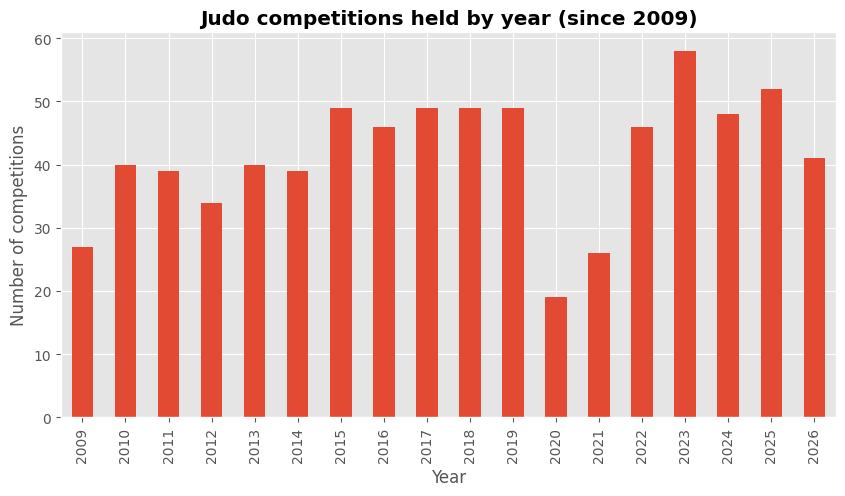

In [11]:
grouped = df.drop_duplicates('competition')['year'].value_counts().sort_index()
grouped = grouped[grouped.index >= 2009]

plt.figure(figsize=(10,5))
grouped.plot.bar()
plt.xlabel('Year')
plt.ylabel('Number of competitions')
plt.title('Judo competitions held by year (since 2009)', fontweight='bold')
plt.show()

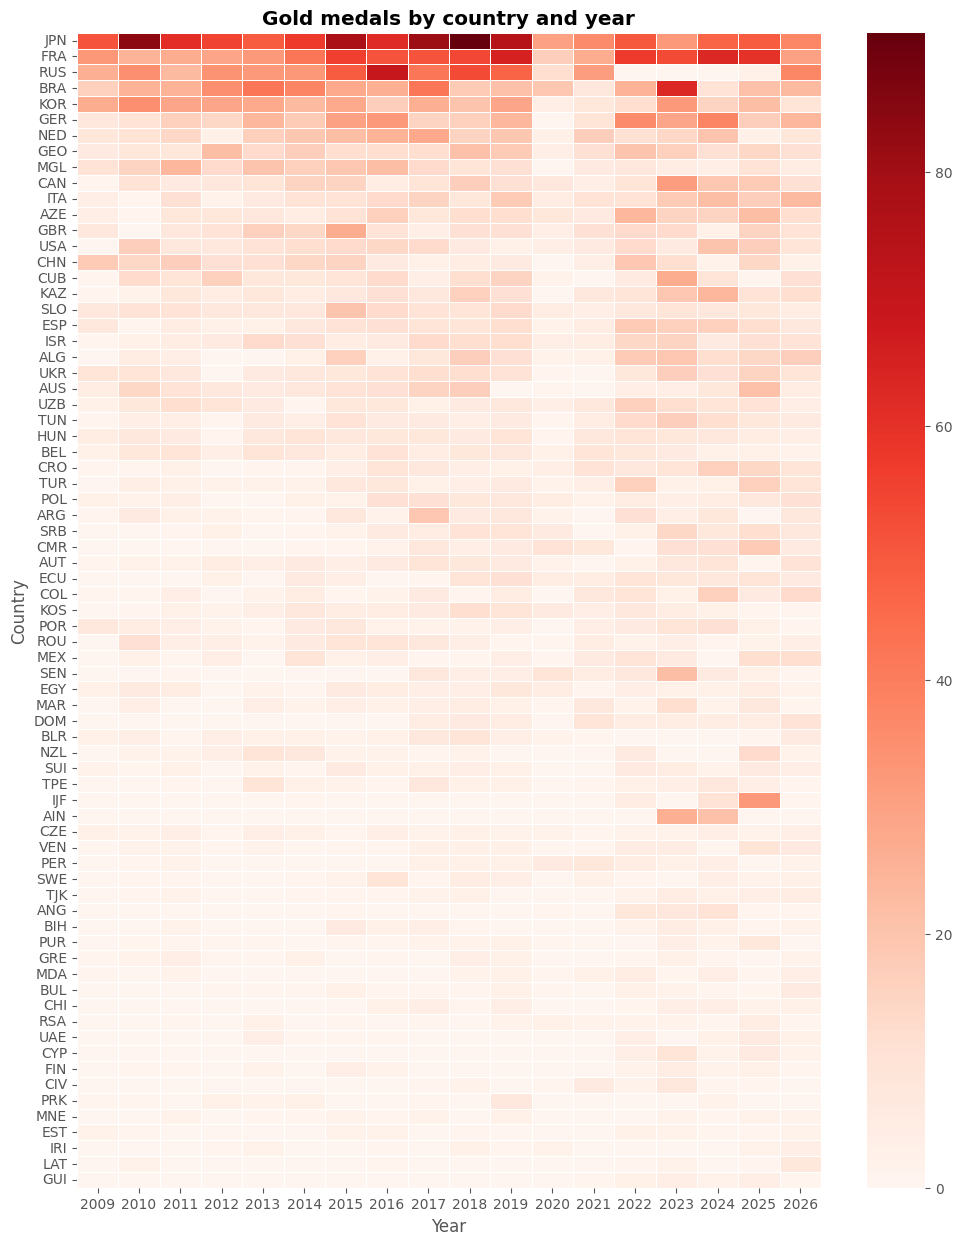

In [12]:
filtered=df[(df['place']==1)&(df['year']>=2009)]
matrix=pd.pivot_table(data=filtered, index='country', columns='year', values='name', aggfunc='count')

matrix = matrix.fillna(0).astype(int)
matrix = matrix.loc[matrix.sum(axis=1).sort_values(ascending=False).index]
matrix['Total'] = matrix.sum(axis=1)
matrix=matrix[matrix['Total']>=15]
matrix=matrix.drop(columns='Total')

plt.figure(figsize=(12, 15))
sns.heatmap(matrix, annot=False, fmt='d', cmap='Reds', linewidths=0.5)
plt.title('Gold medals by country and year', fontweight='bold')
plt.xlabel('Year')
plt.ylabel('Country')
plt.show()

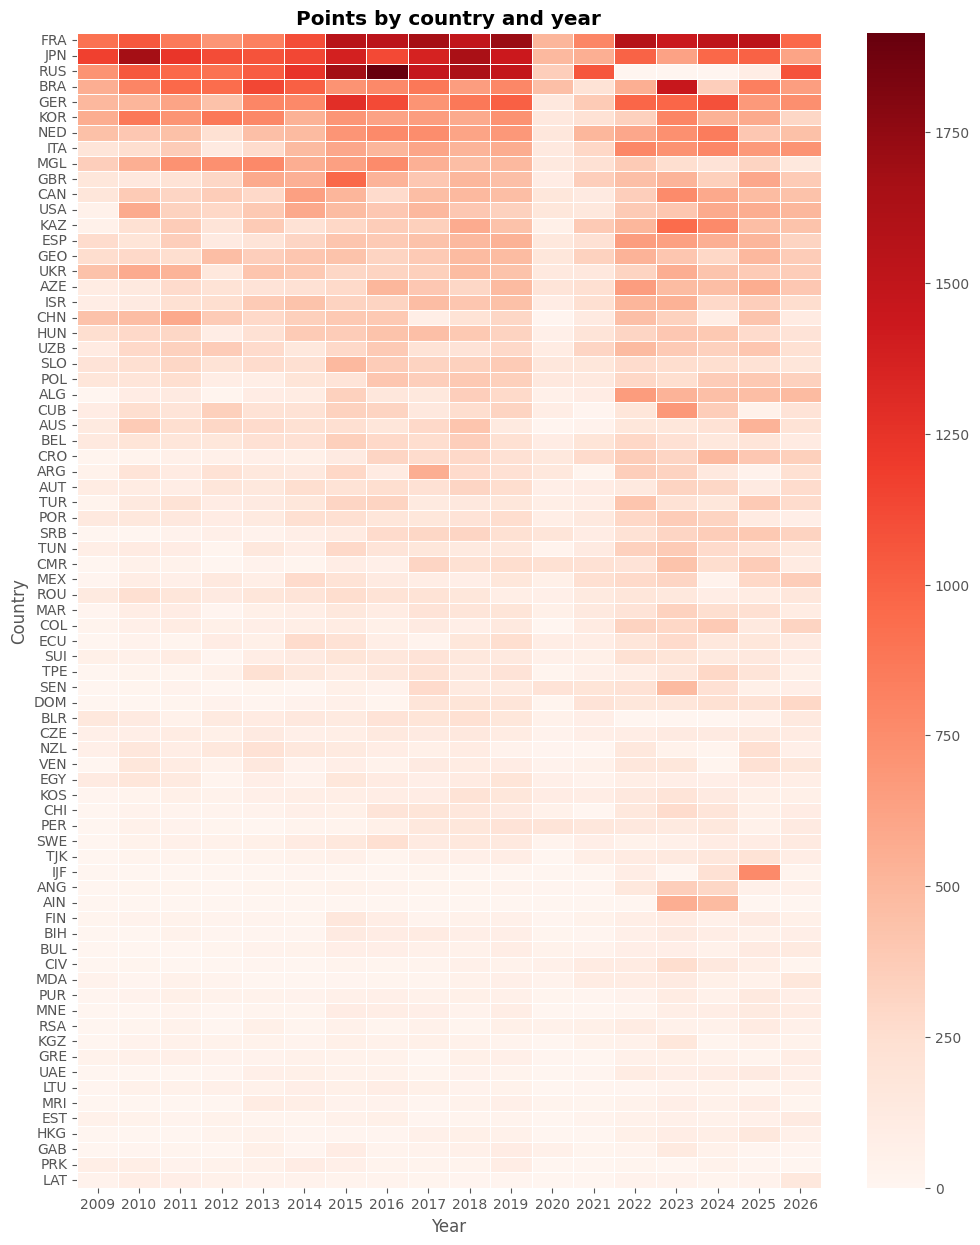

In [13]:
points = {1: 10, 2: 7, 3: 5, 4: 5, 5: 3, 6: 3, 7: 1, 8: 1}
df['points'] = df['place'].map(points)

filtered = df[df['year'] >= 2009]
matrix = pd.pivot_table(data=filtered, index='country', columns='year', values='points', aggfunc='sum')

matrix = matrix.fillna(0).astype(int)
matrix = matrix.loc[matrix.sum(axis=1).sort_values(ascending=False).index]
matrix['Total'] = matrix.sum(axis=1)
matrix = matrix[matrix['Total'] >= 100]
matrix = matrix[matrix['Total'] >= 700]
matrix = matrix.drop(columns='Total')

plt.figure(figsize=(12, 15))
sns.heatmap(matrix, annot=False, fmt='d', cmap='Reds', linewidths=0.5)
plt.title('Points by country and year', fontweight='bold')
plt.xlabel('Year')
plt.ylabel('Country')
plt.show()

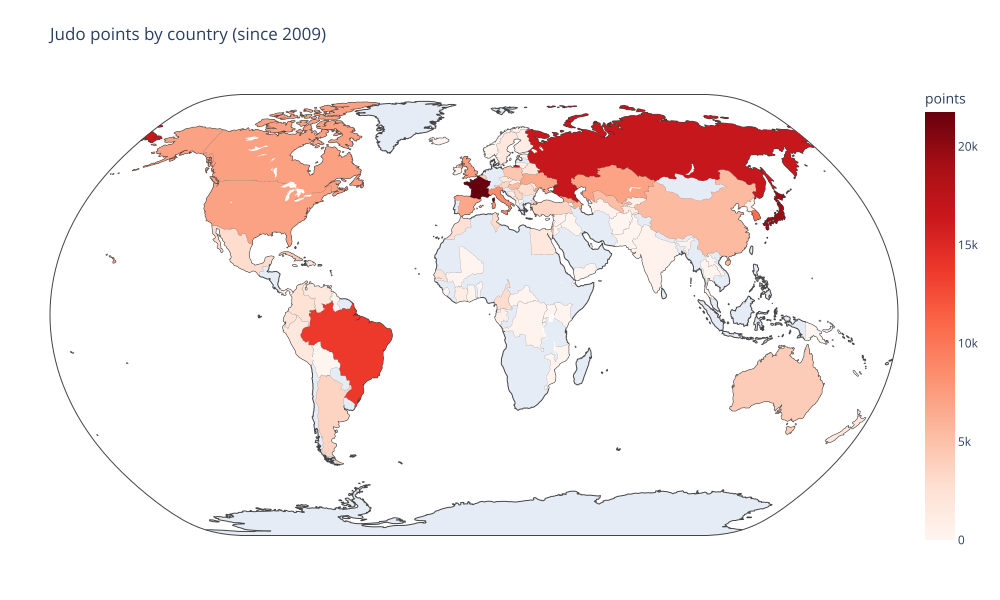

In [14]:
data = df.groupby('country', as_index=False)['points'].sum()

fig = px.choropleth(data, locations='country', color='points', hover_name='country',
                    color_continuous_scale='Reds', title='Judo points by country (since 2009)')

fig.update_traces(marker_line_width=0.1, marker_line_color='black')
fig.update_layout(width=1000, height=600, margin=dict(l=50, r=50, t=80, b=50))
fig.update_geos(projection_type='natural earth')

fig.show('svg')